# 05 · The market today: where diabetes prescribing has moved

**Question:** since 1999–2008, how much have the newer drug classes (GLP-1 and SGLT2, which guidelines now prefer for patients with heart or kidney disease) taken over, and **which doctors and states are behind?**

Data: Medicare Part D 2020–2024 (CMS API), CDC PLACES 2025, openFDA, all collected in notebook 02. Weight-loss brands (Wegovy, Zepbound, Saxenda) are excluded throughout.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))  # make src/ importable when run from notebooks/

import numpy as np
import pandas as pd
import duckdb
import matplotlib.pyplot as plt
from src.config import PROCESSED, FIGURES, SERIES, MUTED, INK2, CLASS_ORDER, ADVANCED, style, update_results
style()

spend = pd.read_parquet(PROCESSED / "spending_by_brand.parquet")
spend = spend[~spend.weight_loss_brand]
claims = pd.read_parquet(PROCESSED / "prescriber_claims.parquet")
state = pd.read_parquet(PROCESSED / "state_claims.parquet")
county = pd.read_parquet(PROCESSED / "county_burden.parquet")
patients = pd.read_parquet(PROCESSED / "patients_profiled.parquet")
con = duckdb.connect()
for name, df in {"spend": spend, "claims": claims, "state": state, "county": county}.items():
    con.register(name, df)

## 1. Market map: Medicare diabetes spending by class, 2020–2024

In [2]:
years = range(2020, 2025)
long = pd.concat([spend.groupby("drug_class")[[f"Tot_Spndng_{y}", f"Tot_Clms_{y}"]].sum()
                     .set_axis(["spend", "claims"], axis=1).assign(year=y) for y in years]).reset_index()
long["advanced"] = long.drug_class.isin(ADVANCED)
tot = long.groupby("year")[["spend", "claims"]].sum()
adv = long[long.advanced].groupby("year")[["spend", "claims"]].sum()
share = (100 * adv / tot).round(1).add_prefix("advanced_share_")
share["total_spend_$B"] = (tot.spend / 1e9).round(1)
share

,advanced_share_spend,advanced_share_claims,total_spend_$B
year,,,
2020,33.0,11.5,34.0
2021,41.2,15.0,39.4
2022,50.6,19.8,46.6
2023,60.9,27.4,60.4
2024,76.0,33.3,59.9


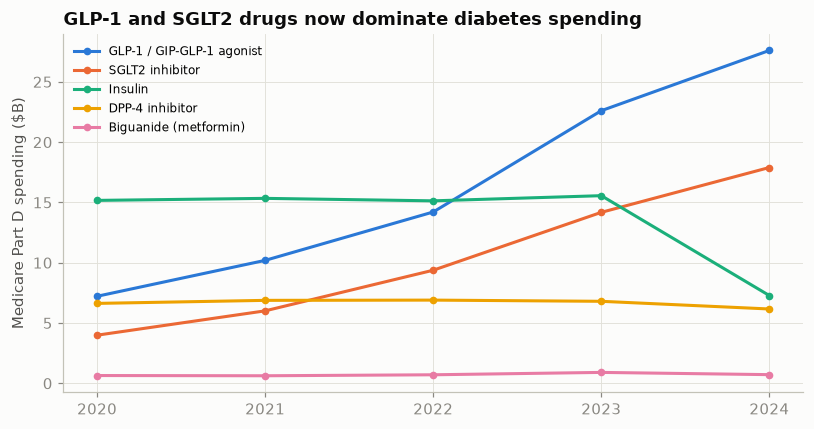

In [3]:
pivot = long.pivot(index="year", columns="drug_class", values="spend").fillna(0) / 1e9
order = [c for c in CLASS_ORDER if c in pivot.columns and pivot[c].max() > 0.3]
fig, ax = plt.subplots(figsize=(7.5, 4))
for i, c in enumerate(sorted(order, key=lambda c: -pivot[c].iloc[-1])):
    ax.plot(pivot.index, pivot[c], lw=2, marker="o", ms=4, color=SERIES[i], label=c)
ax.set_ylabel("Medicare Part D spending ($B)"); ax.set_xticks(list(years))
ax.set_title("GLP-1 and SGLT2 drugs now dominate diabetes spending")
ax.legend(fontsize=8, loc="upper left")
plt.tight_layout(); plt.savefig(FIGURES / "05_spend_by_class.png", dpi=160); plt.show()

GLP-1 and SGLT2 drugs went from **33% to 76%** of Medicare diabetes spending in five years, but only from **12% to 33%** of claims: they're expensive per prescription. Total spending dipped slightly in 2024, which lines up with the 2024 insulin list-price cuts by the three insulin makers and the $35 monthly insulin cap for Medicare patients.

## 2. Then vs. now: the treatment mix

Share of all drug-class uses: in the 1999–2008 hospital data (patients on each class) vs. Medicare Part D claims in 2024. The two sources measure different things (hospital patients vs. outpatient prescriptions), so I compare the **mix**, not the absolute levels.

In [4]:
on_cols = [c for c in patients.columns if c.startswith("on_")]
then = patients[on_cols].sum().rename(lambda c: c[3:])
then = (100 * then / then.sum())
now_claims = claims.groupby("drug_class").Tot_Clms.sum()
now = 100 * now_claims / now_claims.sum()
mix = pd.DataFrame({"1999–2008 hospital patients (%)": then, "2024 Medicare claims (%)": now}).reindex(CLASS_ORDER).fillna(0).round(1)
mix = mix[(mix > 0.5).any(axis=1)]
mix

,1999–2008 hospital patients (%),2024 Medicare claims (%)
Biguanide (metformin),18.4,31.9
Sulfonylurea,24.9,10.6
Thiazolidinedione,11.9,2.7
Meglitinide,1.7,0.3
Insulin,42.9,14.5
DPP-4 inhibitor,0.0,5.2
SGLT2 inhibitor,0.0,15.8
GLP-1 / GIP-GLP-1 agonist,0.0,18.9


Metformin is still the first-line drug (32% of claims, up from 18%), insulin's share fell by about two-thirds, and GLP-1 plus SGLT2 drugs went from **0% to 35%** of the mix.

## 3. Which specialties have adopted the newer classes?

For every specialty with at least 50,000 diabetes claims: how many prescribers, how many claims, and what share of those claims are GLP-1 or SGLT2.

SGLT2 drugs are also approved for heart failure and chronic kidney disease, so cardiology and nephrology numbers partly reflect non-diabetes use. I show GLP-1 and SGLT2 separately so that's visible.

In [5]:
spec = con.sql('''
    SELECT Prscrbr_Type AS specialty,
           COUNT(DISTINCT Prscrbr_NPI) AS prescribers,
           SUM(Tot_Clms) AS diabetes_claims,
           ROUND(100 * SUM(CASE WHEN drug_class IN ('GLP-1 / GIP-GLP-1 agonist', 'SGLT2 inhibitor') THEN Tot_Clms END) / SUM(Tot_Clms), 1) AS advanced_pct,
           ROUND(100 * SUM(CASE WHEN drug_class = 'GLP-1 / GIP-GLP-1 agonist' THEN Tot_Clms END) / SUM(Tot_Clms), 1) AS glp1_pct,
           ROUND(100 * SUM(CASE WHEN drug_class = 'SGLT2 inhibitor' THEN Tot_Clms END) / SUM(Tot_Clms), 1) AS sglt2_pct,
           ROUND(100 * SUM(CASE WHEN drug_class IN ('Biguanide (metformin)', 'Sulfonylurea') THEN Tot_Clms END) / SUM(Tot_Clms), 1) AS metformin_su_pct
    FROM claims GROUP BY 1 HAVING SUM(Tot_Clms) >= 50000
    ORDER BY diabetes_claims DESC
''').df()
spec["specialty"] = spec.specialty.replace({"Student in an Organized Health Care Education/Training Program": "Medical trainee"})
spec["share_of_all_claims_pct"] = (100 * spec.diabetes_claims / claims.Tot_Clms.sum()).round(1)
spec.head(15)

,specialty,prescribers,diabetes_claims,advanced_pct,glp1_pct,sglt2_pct,metformin_su_pct,share_of_all_claims_pct
0,Family Practice,82336,32009158.0,31.0,18.2,12.8,48.6,30.7
1,Internal Medicine,62990,28941734.0,31.1,17.0,14.1,45.6,27.8
2,Nurse Practitioner,86027,18997657.0,36.9,21.4,15.5,41.0,18.2
3,Endocrinology,6076,9379129.0,40.0,27.1,12.8,23.4,9.0
4,Physician Assistant,26841,6146304.0,38.0,22.5,15.5,41.5,5.9
5,General Practice,4723,2387470.0,19.5,8.1,11.4,53.7,2.3
6,Cardiology,13515,1637844.0,82.6,9.6,73.1,13.4,1.6
7,Nephrology,6784,1052798.0,79.7,8.0,71.8,11.0,1.0
8,Geriatric Medicine,1402,543790.0,23.3,10.1,13.2,42.7,0.5
9,Pharmacist,1344,496923.0,37.6,23.6,14.0,36.6,0.5


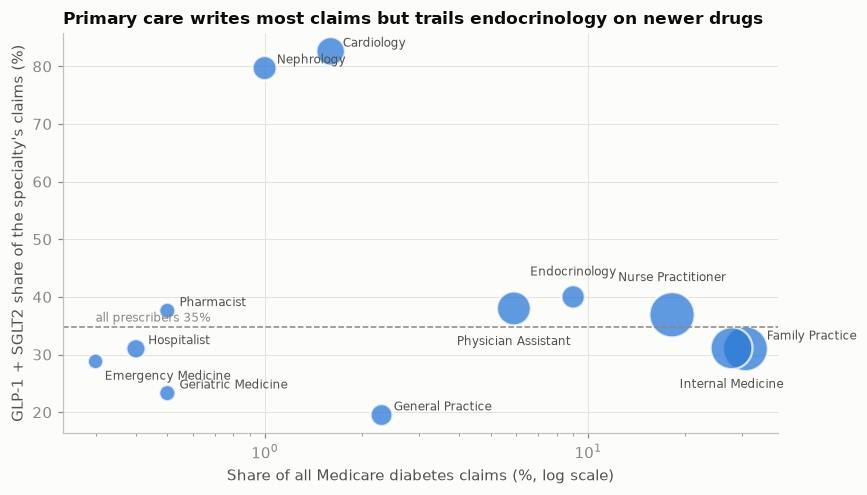

In [6]:
s = spec.head(12)
fig, ax = plt.subplots(figsize=(8, 4.6))
ax.scatter(s.share_of_all_claims_pct, s.advanced_pct, s=np.sqrt(s.prescribers) * 3, color=SERIES[0], alpha=0.75,
           edgecolor="white", linewidth=1.5)
# (dx, dy, alignment) in points, set by hand so labels don't collide
OFFSET = {"Internal Medicine": (0, -26, "center"), "Family Practice": (14, 6, "left"),
          "Nurse Practitioner": (0, 22, "center"), "Physician Assistant": (0, -24, "center"),
          "Endocrinology": (0, 14, "center"), "Emergency Medicine": (6, -12, "left")}
for r in s.itertuples():
    dx, dy, ha = OFFSET.get(r.specialty, (8, 3, "left"))
    ax.annotate(r.specialty, (r.share_of_all_claims_pct, r.advanced_pct), xytext=(dx, dy), textcoords="offset points",
                fontsize=8, color=INK2, ha=ha)
nat = 100 * claims.loc[claims.drug_class.isin(ADVANCED), "Tot_Clms"].sum() / claims.Tot_Clms.sum()
ax.axhline(nat, color=MUTED, ls="--", lw=1); ax.text(0.3, nat + 1, f"all prescribers {nat:.0f}%", ha="left", color=MUTED, fontsize=8)
ax.set_xscale("log"); ax.set_xlabel("Share of all Medicare diabetes claims (%, log scale)")
ax.set_ylabel("GLP-1 + SGLT2 share of the specialty's claims (%)")
ax.set_title("Primary care writes most claims but trails endocrinology on newer drugs", fontsize=11)
plt.tight_layout(); plt.savefig(FIGURES / "05_specialty_map.png", dpi=160); plt.show()

**Family practice, internal medicine and nurse practitioners write 77% of Medicare diabetes claims**, and their GLP-1 + SGLT2 share (31–37%) trails endocrinology (40%, with far more GLP-1). Cardiology and nephrology look like the heaviest adopters, but almost all of that is SGLT2 for heart failure and kidney disease rather than diabetes. General practice (20%) and geriatric medicine (23%) lag the most.

## 4. State adoption vs. disease burden

Adult diabetes prevalence per state (CDC PLACES, county figures weighted by adult population) against each state's GLP-1 + SGLT2 share of Medicare diabetes claims. States that are **high-burden but low-adoption** are the clearest gap. Kentucky and Pennsylvania aren't in the 2025 PLACES county release, so they drop out of this view (both stay in the prescriber analysis in notebook 06, which doesn't need the CDC figures). "High burden" means above the median state.

In [7]:
burden = con.sql('''
    SELECT stateabbr, statedesc,
           SUM(adults_with_diabetes) AS adults_with_diabetes,
           ROUND(100 * SUM(adults_with_diabetes) / SUM(totalpop18plus), 1) AS diabetes_prev_pct,
           ROUND(SUM(OBESITY * totalpop18plus) / SUM(totalpop18plus), 1) AS obesity_prev_pct
    FROM county GROUP BY 1, 2
''').df()
adopt = con.sql('''
    SELECT Prscrbr_Geo_Desc AS statedesc,
           SUM(Tot_Clms) AS diabetes_claims,
           ROUND(100 * SUM(CASE WHEN drug_class IN ('GLP-1 / GIP-GLP-1 agonist', 'SGLT2 inhibitor') THEN Tot_Clms END) / SUM(Tot_Clms), 1) AS advanced_pct
    FROM state GROUP BY 1
''').df()
st = burden.merge(adopt, on="statedesc")
med_prev, med_adopt = st.diabetes_prev_pct.median(), st.advanced_pct.median()
st["quadrant"] = np.select(
    [(st.diabetes_prev_pct > med_prev) & (st.advanced_pct < med_adopt),
     (st.diabetes_prev_pct > med_prev) & (st.advanced_pct >= med_adopt),
     (st.diabetes_prev_pct <= med_prev) & (st.advanced_pct < med_adopt)],
    ["High burden, low adoption", "High burden, high adoption", "Low burden, low adoption"], "Low burden, high adoption")
missing = sorted(set(adopt.statedesc) - set(burden.statedesc))
print(f"{len(st)} areas matched (48 states + DC). Not in the 2025 PLACES county release or not a state: {missing}")
print(f"Median prevalence {med_prev}%, median adoption {med_adopt}%")
corr = st[["diabetes_prev_pct", "advanced_pct"]].corr().iloc[0, 1]
print(f"Correlation between burden and adoption: {corr:.2f}")
st[st.quadrant == "High burden, low adoption"].sort_values("adults_with_diabetes", ascending=False)

49 areas matched (48 states + DC). Not in the 2025 PLACES county release or not a state: ['Armed Forces Central/South America', 'Armed Forces Europe', 'Armed Forces Pacific', 'Foreign Country', 'Guam', 'Kentucky', 'Northern Mariana Islands', 'Pennsylvania', 'Puerto Rico', 'Unknown', 'Virgin Islands']
Median prevalence 11.7%, median adoption 33.9%
Correlation between burden and adoption: 0.21


,stateabbr,statedesc,adults_with_diabetes,diabetes_prev_pct,obesity_prev_pct,diabetes_claims,advanced_pct,quadrant
1,FL,Florida,2460085.911,13.5,31.9,8673705.0,30.6,"High burden, low adoption"
14,OH,Ohio,1220001.853,13.2,37.1,4926459.0,31.9,"High burden, low adoption"
25,VA,Virginia,851712.106,12.5,34.5,2624436.0,31.1,"High burden, low adoption"
44,MD,Maryland,600502.985,12.5,35.1,1591475.0,33.2,"High burden, low adoption"
46,NV,Nevada,302231.559,12.0,31.3,838573.0,33.7,"High burden, low adoption"
21,NM,New Mexico,219121.707,13.2,34.1,634649.0,30.9,"High burden, low adoption"


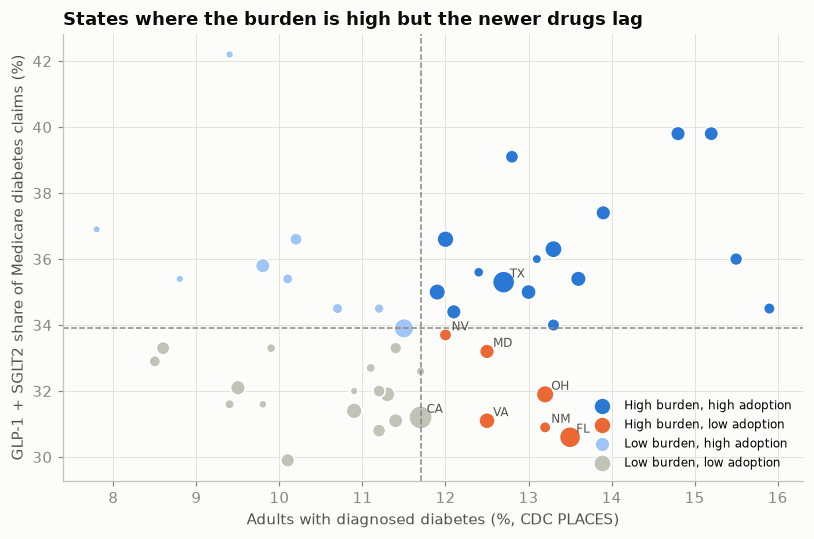

In [8]:
fig, ax = plt.subplots(figsize=(7.5, 5))
colors = {"High burden, low adoption": SERIES[1], "High burden, high adoption": SERIES[0],
          "Low burden, low adoption": "#c3c2b7", "Low burden, high adoption": "#9ec5f4"}
for q, d in st.groupby("quadrant"):
    ax.scatter(d.diabetes_prev_pct, d.advanced_pct, s=np.sqrt(d.adults_with_diabetes) / 8, color=colors[q],
               edgecolor="white", linewidth=1.2, label=q)
for r in st.itertuples():
    if r.quadrant == "High burden, low adoption" or r.adults_with_diabetes > 2e6:
        ax.annotate(r.stateabbr, (r.diabetes_prev_pct, r.advanced_pct), xytext=(4, 3), textcoords="offset points", fontsize=8, color=INK2)
ax.axvline(med_prev, color=MUTED, ls="--", lw=1); ax.axhline(med_adopt, color=MUTED, ls="--", lw=1)
ax.set_xlabel("Adults with diagnosed diabetes (%, CDC PLACES)"); ax.set_ylabel("GLP-1 + SGLT2 share of Medicare diabetes claims (%)")
ax.set_title("States where the burden is high but the newer drugs lag"); ax.legend(fontsize=8, loc="lower right")
plt.tight_layout(); plt.savefig(FIGURES / "05_state_quadrant.png", dpi=160); plt.show()

In [9]:
spec.to_parquet(PROCESSED / "specialty_summary.parquet", index=False)
st.to_parquet(PROCESSED / "state_summary.parquet", index=False)
update_results("market", {
    "by_year": share.reset_index().to_dict("records"),
    "spend_by_class": long[["year", "drug_class", "spend", "claims"]].to_dict("records"),
    "mix": mix.reset_index().rename(columns={"index": "drug_class"}).to_dict("records"),
    "specialties": spec.head(12).to_dict("records"),
    "national_advanced_pct": round(nat, 1),
    "states": st.to_dict("records"),
    "state_medians": {"prev": med_prev, "adopt": med_adopt, "corr": round(corr, 2)},
    "total_prescribers": int(claims.Prscrbr_NPI.nunique()),
    "total_claims": float(claims.Tot_Clms.sum()),
})
print("saved")

saved
